In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay, roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer 
print('import done')

import done


In [2]:
df = pd.read_csv('../data/IMDB Dataset.csv')

In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [5]:
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [6]:
df.duplicated().sum()

np.int64(418)

In [7]:
df = df.drop_duplicates(subset='review', keep='first')

In [8]:
df['review']= (df['review']
      .str.lower()
      .str.replace( "[!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~]",'',regex = True)
      .str.replace(r"<.*?>", " ", regex=True)   # remove HTML tags
      .str.replace(r"\bbr\b", " ", regex=True) # remove leftover 'br'
      .str.replace(r"\s+", " ", regex=True)    # normalize spaces
      .str.strip()
              )

In [9]:
from wordcloud import WordCloud

pos_text = ' '.join(word for word in df['review'][df['sentiment']== 'positive'])
wordcloud = WordCloud(height = 600, width = 1000, max_font_size= 150)
plt.figure(figsize=(15,12))
plt.imshow(wordcloud.generate(pos_text), interpolation= 'bilinear')
plt.axis('off')
plt.show()

neg_text = ' '.join(word for word in df['review'][df['sentiment']== 'negative'])
wordcloud = WordCloud(height = 600, width = 1000, max_font_size= 150,background_color='white' )
plt.figure(figsize=(20,15))
plt.imshow(wordcloud.generate(neg_text), interpolation= 'bilinear')
plt.axis('off')
plt.show()

In [10]:
df['review'][1]

'a wonderful little production the filming technique is very unassuming very oldtimebbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are extremely well chosen michael sheen not only has got all the polari but he has all the voices down pat too you can truly see the seamless editing guided by the references to williams diary entries not only is it well worth the watching but it is a terrificly written and performed piece a masterful production about one of the great masters of comedy and his life the realism really comes home with the little things the fantasy of the guard which rather than use the traditional dream techniques remains solid then disappears it plays on our knowledge and our senses particularly with the scenes concerning orton and halliwell and the sets particularly of their flat with halliwells murals decorating every surface are terribly well done'

In [11]:
vectorizer = TfidfVectorizer( ngram_range=(1,2), max_features=10000, min_df=2, max_df=0.7, stop_words='english')

In [12]:
reviews = df['review']

In [13]:
sentiments = (df['sentiment']=='positive').astype('int8')

In [14]:
X_train, X_test, y_train, y_test = train_test_split(reviews, sentiments, test_size=0.2, random_state=1)

In [15]:
X_train_vectd = vectorizer.fit_transform(X_train)
x_test_vectd = vectorizer.transform(X_test)

In [16]:
y_train

17824    0
41082    0
35822    1
40       0
19775    0
        ..
44035    1
32696    0
5195     0
12195    0
33189    1
Name: sentiment, Length: 39665, dtype: int8

In [17]:
model = LogisticRegression(random_state=1)
model.fit(X_train_vectd, y_train)
y_pred = model.predict(x_test_vectd)

In [18]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.8882726631037612
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      5033
           1       0.87      0.91      0.89      4884

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



In [19]:
print(roc_auc_score(y_test, y_pred))

0.8885414210518522


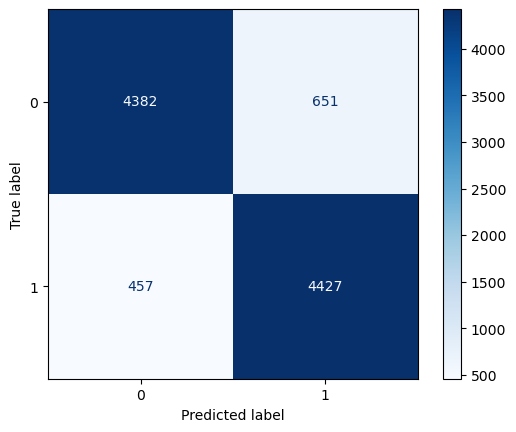

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=model.classes_, cmap = 'Blues')
plt.show()

In [21]:
compare = pd.DataFrame({'Actual_score':y_test, 'Predicted_score':y_pred}) 

In [22]:
compare.head(20)

,Actual_score,Predicted_score
26819,1,0
26589,1,1
40630,1,1
2929,1,1
13011,1,1
14727,0,0
11914,1,1
32414,1,1
8757,0,1
37159,1,1


In [23]:
from sklearn.ensemble import RandomForestClassifier

In [31]:
rf_model = RandomForestClassifier(random_state=1, n_estimators= 100)

In [32]:
rf_model.fit(X_train_vectd, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
rf_y_pred = rf_model.predict(x_test_vectd)
print("Accuracy for Random Forest:",accuracy_score(y_test, rf_y_pred))
print(classification_report(y_test, rf_y_pred))

Accuracy for Random Forest: 0.8469295149742866
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      5033
           1       0.84      0.85      0.85      4884

    accuracy                           0.85      9917
   macro avg       0.85      0.85      0.85      9917
weighted avg       0.85      0.85      0.85      9917



In [34]:
import joblib as jbl

In [35]:
jbl.dump(model,"model.joblib")

['model.joblib']

In [36]:
jbl.dump(vectorizer, "vectorizer.joblib")

['vectorizer.joblib']